# Clasificación de cáncer de mama (Wisconsin Diagnostic)

Proyecto de clasificación binaria sobre el dataset [Breast Cancer Wisconsin (Diagnostic)](https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data). El objetivo es distinguir tumores **malignos** de **benignos** a partir de características nucleares extraídas de una aspiración con aguja fina (FNA).

**Enfoque clínico.** Un falso negativo (tumor maligno clasificado como benigno) es más costoso que un falso positivo. Por eso la métrica principal es el **recall de la clase maligna**, complementada con F1, ROC-AUC y la matriz de confusión.

**Protocolo.** Split estratificado *antes* de cualquier transformación. Escalado y búsqueda de hiperparámetros solo sobre el conjunto de entrenamiento, encapsulados en un `Pipeline` de scikit-learn.

## 1. Carga y calidad de los datos

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)
RANDOM_STATE = 42

ROOT = Path.cwd()
if not (ROOT / "data" / "data.csv").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "data.csv"

df = pd.read_csv(DATA_PATH)
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [2]:
print(f"Filas, columnas: {df.shape}")
print(f"Ruta: {DATA_PATH.resolve()}")
df.info()

Filas, columnas: (569, 33)
Ruta: /home/lukas/proyectos/DS-Project-breast-cancer-wisconsin/data/data.csv
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    

In [3]:
missing = df.isna().sum()
missing[missing > 0]

Unnamed: 32    569
dtype: int64

Hay 569 muestras y 33 columnas. `id` no aporta señal clínica. `Unnamed: 32` está vacía (artefacto del CSV de Kaggle). El resto de variables son numéricas; `diagnosis` es la etiqueta (`M` = maligno, `B` = benigno).

In [4]:
df_clean = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")
df_clean["diagnosis"] = df_clean["diagnosis"].map({"M": 1, "B": 0}).astype(int)

assert df_clean.isna().sum().sum() == 0
assert set(df_clean["diagnosis"].unique()) == {0, 1}

conteo = df_clean["diagnosis"].value_counts().sort_index()
print(conteo.rename(index={0: "Benigno (0)", 1: "Maligno (1)"}))
print(f"Proporción malignos: {conteo[1] / conteo.sum():.1%}")

diagnosis
Benigno (0)    357
Maligno (1)    212
Name: count, dtype: int64
Proporción malignos: 37.3%


## 2. Análisis exploratorio

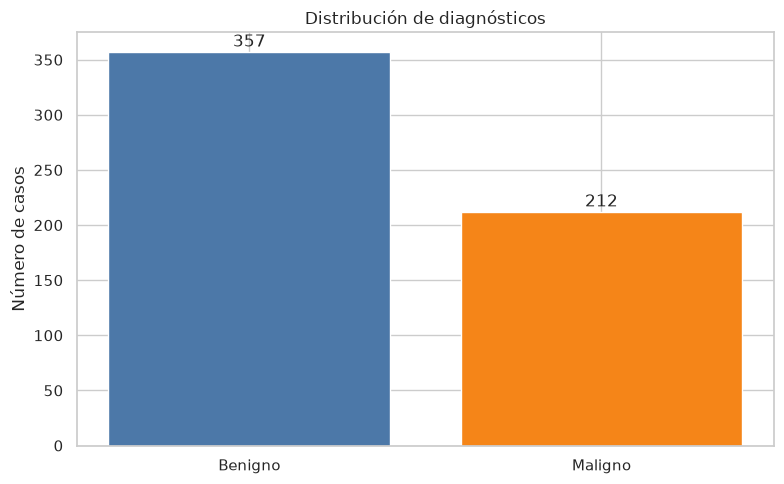

In [5]:
fig, ax = plt.subplots()
etiquetas = ["Benigno", "Maligno"]
colores = ["#4C78A8", "#F58518"]
ax.bar(etiquetas, [conteo[0], conteo[1]], color=colores)
ax.set_ylabel("Número de casos")
ax.set_title("Distribución de diagnósticos")
for i, n in enumerate([conteo[0], conteo[1]]):
    ax.text(i, n + 5, str(n), ha="center")
plt.tight_layout()
plt.show()

Hay desbalance moderado (357 benignos vs 212 malignos, ~37% positivos). No es extremo, pero justifica `class_weight="balanced"` para no sesgar el modelo hacia la clase mayoritaria.

In [6]:
df_clean.drop(columns=["diagnosis"]).describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
texture_mean,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
perimeter_mean,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
area_mean,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
smoothness_mean,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
compactness_mean,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
concavity_mean,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
concave points_mean,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
symmetry_mean,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
fractal_dimension_mean,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


In [7]:
corr_con_target = (
    df_clean.corr(numeric_only=True)["diagnosis"]
    .drop("diagnosis")
    .abs()
    .sort_values(ascending=False)
)
corr_con_target.head(10).to_frame(" |corr| con diagnosis")

,|corr| con diagnosis
concave points_worst,0.793566
perimeter_worst,0.782914
concave points_mean,0.776614
radius_worst,0.776454
perimeter_mean,0.742636
area_worst,0.733825
radius_mean,0.730029
area_mean,0.708984
concavity_mean,0.696360
concavity_worst,0.659610


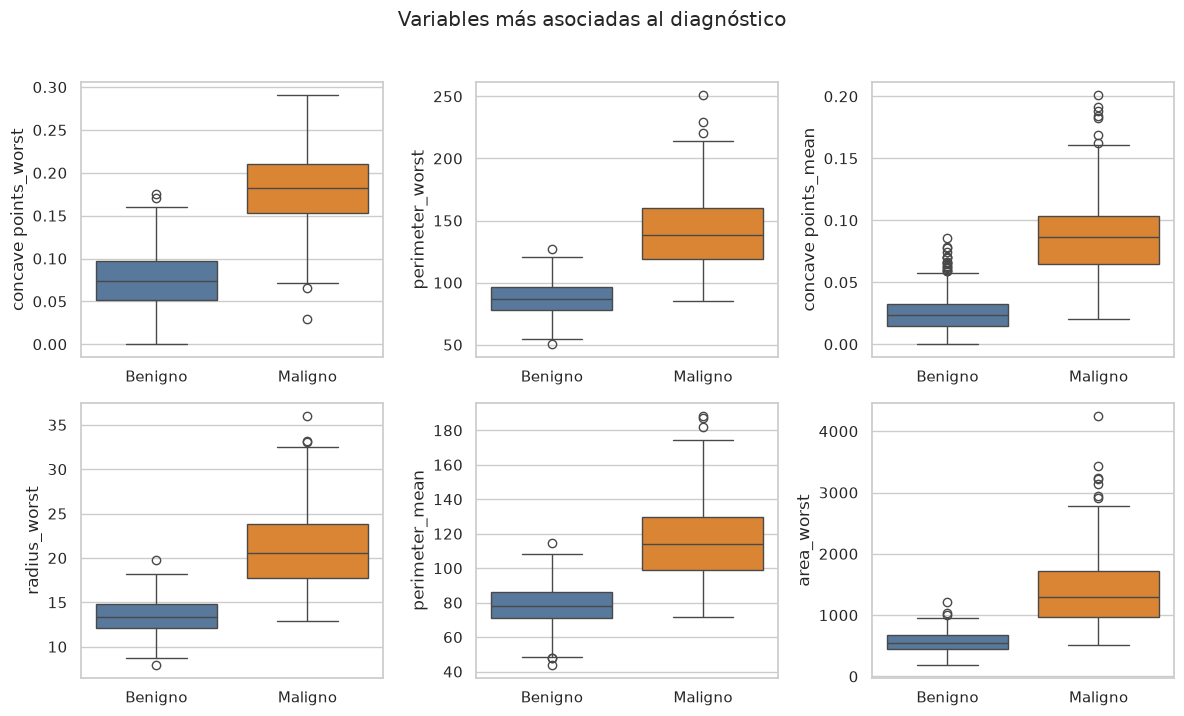

In [8]:
top_features = corr_con_target.head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.ravel(), top_features):
    sns.boxplot(
        data=df_clean,
        x="diagnosis",
        y=col,
        hue="diagnosis",
        palette=colores,
        legend=False,
        ax=ax,
    )
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Benigno", "Maligno"])
    ax.set_xlabel("")
fig.suptitle("Variables más asociadas al diagnóstico", y=1.02)
plt.tight_layout()
plt.show()

Las variables de tamaño y de irregularidad del contorno (`concave points`, `perimeter`, `radius`, `concavity`, en especial sus valores **worst**) separan bien ambas clases: los malignos tienden a núcleos más grandes y más cóncavos.

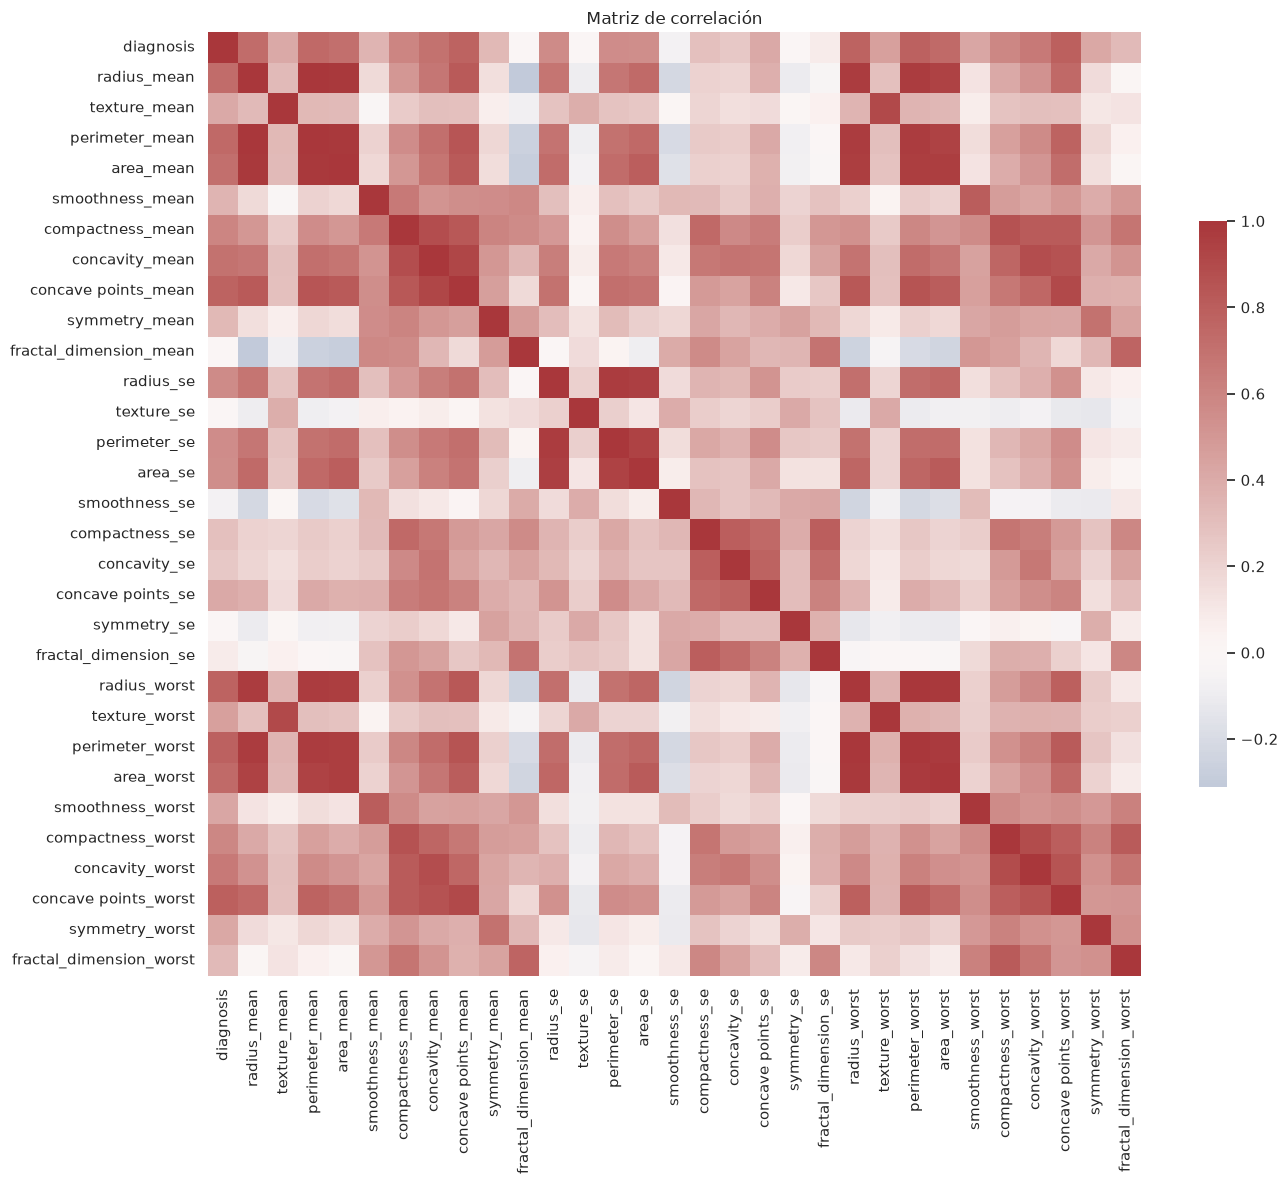

In [9]:
corr = df_clean.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(corr, cmap="vlag", center=0, ax=ax, cbar_kws={"shrink": 0.6})
ax.set_title("Matriz de correlación")
plt.tight_layout()
plt.show()

In [10]:
size_cols = [
    "radius_mean",
    "perimeter_mean",
    "area_mean",
    "radius_worst",
    "perimeter_worst",
    "area_worst",
]
df_clean[size_cols].corr().round(3)

,radius_mean,perimeter_mean,area_mean,radius_worst,perimeter_worst,area_worst
radius_mean,1.000,0.998,0.987,0.970,0.965,0.941
perimeter_mean,0.998,1.000,0.987,0.969,0.970,0.942
area_mean,0.987,0.987,1.000,0.963,0.959,0.959
radius_worst,0.970,0.969,0.963,1.000,0.994,0.984
perimeter_worst,0.965,0.970,0.959,0.994,1.000,0.978
area_worst,0.941,0.942,0.959,0.984,0.978,1.000


**Multicolinealidad.** `radius`, `perimeter` y `area` (mean y worst) están casi duplicadas (correlaciones > 0.9): son transformaciones geométricas del mismo núcleo. No se eliminan a priori: la regresión logística irá regularizada (`C`) y el random forest no se ve afectado por colinealidad en predicción. Sí hay que leer los coeficientes de LR con cautela: la importancia se reparte entre variables redundantes.

Este EDA describe el dataset. **No se usa para elegir features.** La selección, si la hubiera, iría solo sobre el train, dentro del pipeline.

## 3. Protocolo de modelado

1. Partición 80/20 **estratificada**, `random_state=42`.
2. `Pipeline`: el escalado se ajusta solo con train (en LR). Random forest no escala.
3. `GridSearchCV` con `StratifiedKFold(5)` sobre train. `refit=True` reentrena el mejor modelo en todo el train.
4. El test se usa **una sola vez**, al evaluar.
5. Scoring de la búsqueda: `recall` (clase positiva = maligno).

In [11]:
X = df_clean.drop(columns=["diagnosis"])
y = df_clean["diagnosis"]
feature_names = X.columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"Train: {X_train.shape[0]}  |  Test: {X_test.shape[0]}")
print(f"Malignos train: {y_train.mean():.1%}  |  Malignos test: {y_test.mean():.1%}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def evaluar(nombre, modelo, X_test, y_test):
    y_pred = modelo.predict(X_test)
    if hasattr(modelo, "predict_proba"):
        y_score = modelo.predict_proba(X_test)[:, 1]
    else:
        y_score = modelo.decision_function(X_test)
    metrics = {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (M)": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        "Recall (M)": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        "F1 (M)": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_score),
    }
    print(nombre)
    print(classification_report(y_test, y_pred, target_names=["Benigno", "Maligno"], zero_division=0))
    return metrics, y_pred, y_score

Train: 455  |  Test: 114
Malignos train: 37.4%  |  Malignos test: 36.8%


## 4. Baseline

In [12]:
dummy = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
dummy.fit(X_train, y_train)
metricas = []

m, _, _ = evaluar("Dummy (mayoritaria)", dummy, X_test, y_test)
metricas.append(m)

Dummy (mayoritaria)
              precision    recall  f1-score   support

     Benigno       0.63      1.00      0.77        72
     Maligno       0.00      0.00      0.00        42

    accuracy                           0.63       114
   macro avg       0.32      0.50      0.39       114
weighted avg       0.40      0.63      0.49       114



## 5. Regresión logística

`StandardScaler` va *dentro* del pipeline. `class_weight="balanced"` compensa el desbalance. `GridSearchCV` reentrena el mejor (`C`, `solver`) sobre todo el train.

In [13]:
pipe_lr = Pipeline(
    [
        ("scaler", StandardScaler()),
        (
            "clf",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)
grid_lr = {
    "clf__C": [0.01, 0.1, 1, 10, 100],
    "clf__solver": ["lbfgs", "liblinear"],
}
gs_lr = GridSearchCV(
    pipe_lr,
    grid_lr,
    cv=cv,
    scoring="recall",
    n_jobs=-1,
    refit=True,
)
gs_lr.fit(X_train, y_train)

print("Mejores hiperparámetros:", gs_lr.best_params_)
print(f"Recall CV (train): {gs_lr.best_score_:.4f}")

cv_lr = pd.DataFrame(gs_lr.cv_results_)[
    ["param_clf__C", "param_clf__solver", "mean_test_score", "std_test_score"]
].sort_values("mean_test_score", ascending=False)
cv_lr.head(6)

Mejores hiperparámetros: {'clf__C': 0.1, 'clf__solver': 'liblinear'}
Recall CV (train): 0.9588


,param_clf__C,param_clf__solver,mean_test_score,std_test_score
4,1.00,lbfgs,0.958824,0.029994
3,0.10,liblinear,0.958824,0.014409
5,1.00,liblinear,0.958824,0.029994
1,0.01,liblinear,0.952941,0.023529
2,0.10,lbfgs,0.952941,0.023529
6,10.00,lbfgs,0.947059,0.034300


Logistic Regression
              precision    recall  f1-score   support

     Benigno       0.99      1.00      0.99        72
     Maligno       1.00      0.98      0.99        42

    accuracy                           0.99       114
   macro avg       0.99      0.99      0.99       114
weighted avg       0.99      0.99      0.99       114



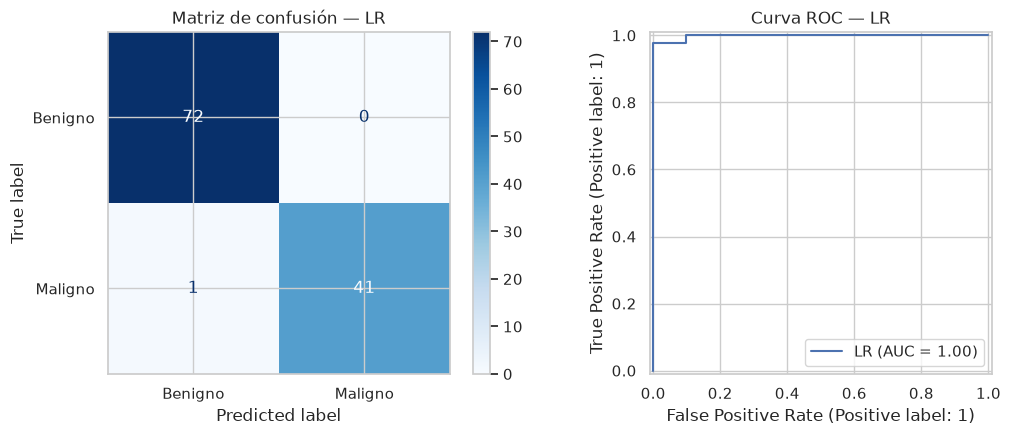

In [14]:
m, pred_lr, score_lr = evaluar(
    "Logistic Regression", gs_lr.best_estimator_, X_test, y_test
)
metricas.append(m)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_estimator(
    gs_lr.best_estimator_,
    X_test,
    y_test,
    display_labels=["Benigno", "Maligno"],
    cmap="Blues",
    ax=axes[0],
)
axes[0].set_title("Matriz de confusión — LR")
RocCurveDisplay.from_estimator(
    gs_lr.best_estimator_, X_test, y_test, ax=axes[1], name="LR"
)
axes[1].set_title("Curva ROC — LR")
plt.tight_layout()
plt.show()

## 6. Random forest

No requiere escalado. Misma partición, mismo CV, mismo scoring. El grid se mantiene acotado: en este dataset los árboles no profundizan tanto como para que `max_depth` alto cambie el resultado.

In [15]:
pipe_rf = Pipeline(
    [
        (
            "clf",
            RandomForestClassifier(
                class_weight="balanced",
                random_state=RANDOM_STATE,
            ),
        )
    ]
)
grid_rf = {
    "clf__n_estimators": [100, 200, 400],
    "clf__max_depth": [5, 10, None],
    "clf__min_samples_leaf": [1, 2],
}
gs_rf = GridSearchCV(
    pipe_rf,
    grid_rf,
    cv=cv,
    scoring="recall",
    n_jobs=-1,
    refit=True,
)
gs_rf.fit(X_train, y_train)

print("Mejores hiperparámetros:", gs_rf.best_params_)
print(f"Recall CV (train): {gs_rf.best_score_:.4f}")

Mejores hiperparámetros: {'clf__max_depth': 5, 'clf__min_samples_leaf': 2, 'clf__n_estimators': 100}
Recall CV (train): 0.9588


Random Forest
              precision    recall  f1-score   support

     Benigno       0.96      0.99      0.97        72
     Maligno       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



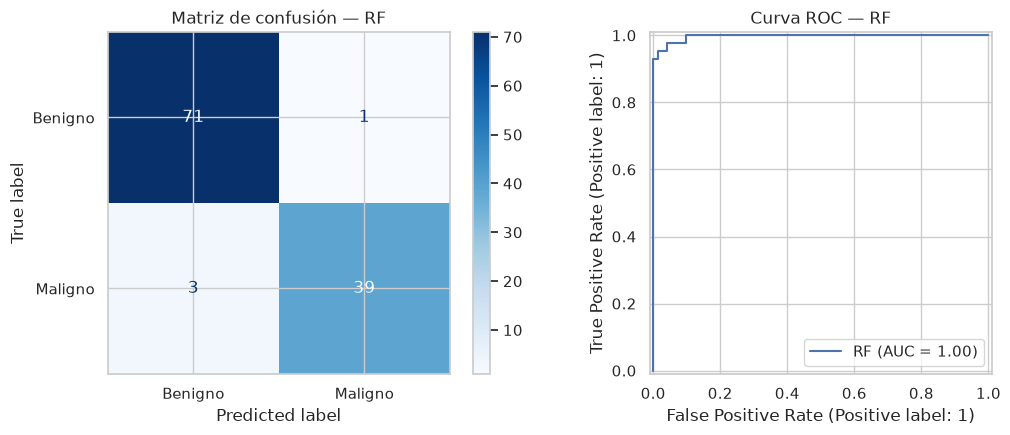

In [16]:
m, pred_rf, score_rf = evaluar(
    "Random Forest", gs_rf.best_estimator_, X_test, y_test
)
metricas.append(m)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_estimator(
    gs_rf.best_estimator_,
    X_test,
    y_test,
    display_labels=["Benigno", "Maligno"],
    cmap="Blues",
    ax=axes[0],
)
axes[0].set_title("Matriz de confusión — RF")
RocCurveDisplay.from_estimator(
    gs_rf.best_estimator_, X_test, y_test, ax=axes[1], name="RF"
)
axes[1].set_title("Curva ROC — RF")
plt.tight_layout()
plt.show()

## 7. Comparación

In [17]:
resultados = pd.DataFrame(metricas).set_index("Modelo")
resultados.round(4).sort_values("Recall (M)", ascending=False)

,Accuracy,Precision (M),Recall (M),F1 (M),ROC-AUC
Modelo,,,,,
Logistic Regression,0.9912,1.000,0.9762,0.9880,0.9977
Random Forest,0.9649,0.975,0.9286,0.9512,0.9964
Dummy (mayoritaria),0.6316,0.000,0.0000,0.0000,0.5000


## 8. Interpretación

Los coeficientes de LR (sobre features estandarizadas) indican dirección y magnitud de la asociación, con la salvedad de la multicolinealidad. Las importancias de RF miden reducción de impureza, no causalidad.

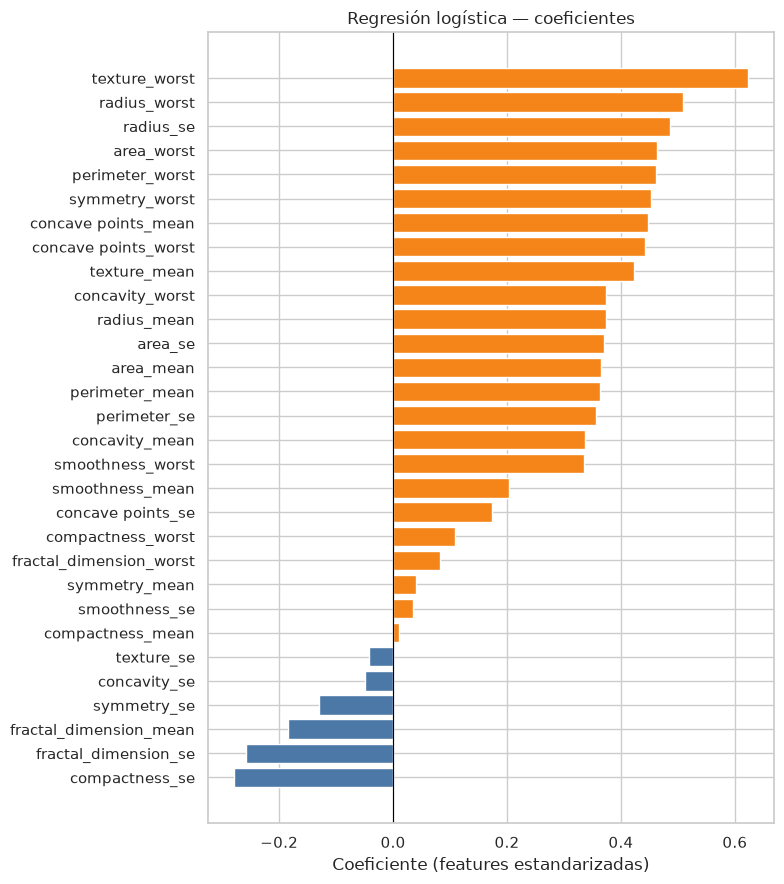

In [18]:
lr_clf = gs_lr.best_estimator_.named_steps["clf"]
coef = pd.Series(lr_clf.coef_[0], index=feature_names).sort_values()

fig, ax = plt.subplots(figsize=(8, 9))
colores_coef = np.where(coef >= 0, "#F58518", "#4C78A8")
ax.barh(coef.index, coef.values, color=colores_coef)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coeficiente (features estandarizadas)")
ax.set_title("Regresión logística — coeficientes")
plt.tight_layout()
plt.show()

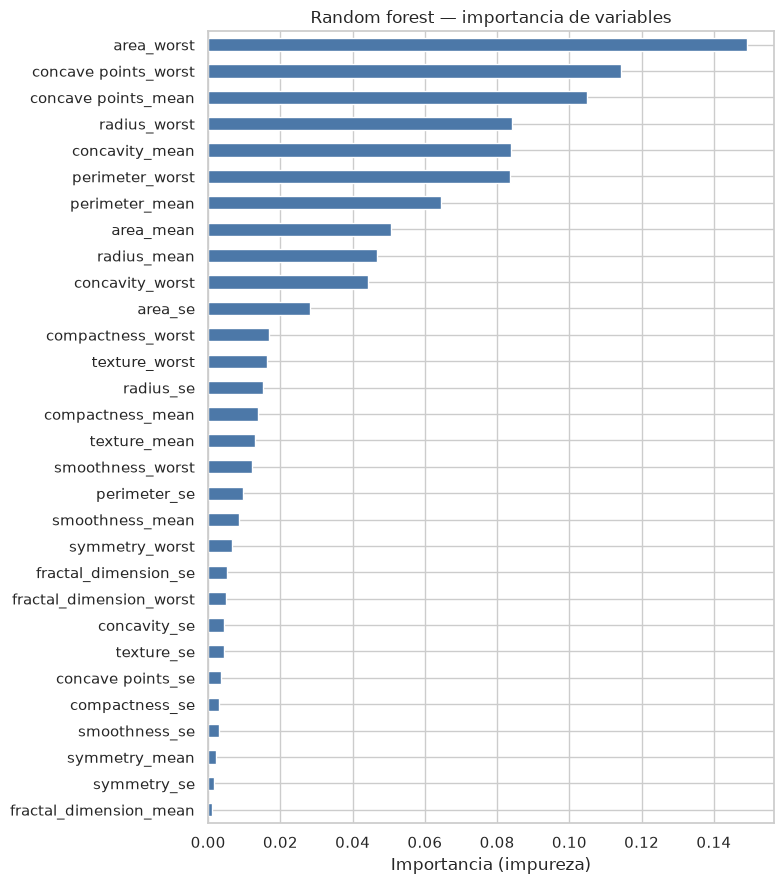

In [19]:
rf_clf = gs_rf.best_estimator_.named_steps["clf"]
imp = pd.Series(rf_clf.feature_importances_, index=feature_names).sort_values()

fig, ax = plt.subplots(figsize=(8, 9))
imp.plot(kind="barh", ax=ax, color="#4C78A8")
ax.set_xlabel("Importancia (impureza)")
ax.set_title("Random forest — importancia de variables")
plt.tight_layout()
plt.show()

## 9. Conclusiones

- El protocolo evita *data leakage*: el test no interviene en el escalado ni en la búsqueda de hiperparámetros.
- Dummy (siempre benigno) logra accuracy 0.63 y **recall maligno 0**. Accuracy sola engaña.
- **Regresión logística** es el mejor modelo en test: accuracy 0.991, recall maligno **0.976**, F1 0.988, ROC-AUC 0.998 (1 falso negativo, 0 falsos positivos en 114 casos).
- Random forest queda cerca (recall 0.929, ROC-AUC 0.996) pero pierde más malignos. En este problema, LR regularizada es preferible: más simple y mejor recall.
- `concave points`, `perimeter` y `radius` (sobre todo *worst*) concentran la señal: núcleos más grandes e irregulares se asocian a malignidad.
- Radius / perimeter / area son geométricamente redundantes. Sirven para predecir; no hay que interpretar cada coeficiente de LR como efecto independiente.
- Limitaciones: 569 muestras, un solo centro, features ya diseñadas (no hay imagen cruda). No sustituye un diagnóstico clínico.
- Siguiente paso razonable: calibrar el umbral según el coste de un falso negativo, o validar en un hospital distinto.